<a href="https://colab.research.google.com/github/AKASHRAJPUT2006/Offline_Hindi_Voice_Assistant-on-Raspberry-pi5-/blob/main/LAWN_Intelligent_UAV_Handover.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intelligent UAV Handover Simulation — LAWN / 6G-inspired

**Revised, compact, cell-by-cell implementation**

This notebook compares:
1. **A3 baseline:** RSRP advantage + hysteresis + time-to-trigger (TTT).
2. **ISAC-assisted:** communication trigger OR idealized distance-sensing trigger.
3. **LSTM predictive:** one-step-ahead RSRP prediction from past mobility, distance and RSRP history.

All three strategies are evaluated on the **same independent held-out trajectory and radio realization**.

**Scope and assumptions:** system-level simulation only; not a 3GPP-compliant stack. The sensing distance is idealized, the channel is simplified, and throughput is a Shannon-style estimate. Handover interruption is modeled as a fixed service interruption after a successful handover.

## 0. Setup

Run in Google Colab. TensorFlow is required for the LSTM section; the A3 and ISAC simulation logic uses NumPy and pandas.

In [1]:
!pip -q install tensorflow

## 1. Imports and configuration

Change parameters here rather than editing multiple cells. The defaults are starting assumptions, not calibrated field measurements.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from dataclasses import dataclass, asdict
from typing import Optional

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

@dataclass
class SimulationConfig:
    area_x_m: float = 2000.0
    area_y_m: float = 2000.0
    bs_height_m: float = 30.0
    drone_min_alt_m: float = 56.0
    drone_max_alt_m: float = 146.0
    duration_s: float = 200.0
    dt_s: float = 0.1
    min_speed_mps: float = 5.0
    max_speed_mps: float = 22.0
    waypoint_reach_m: float = 45.0
    carrier_frequency_ghz: float = 2.0
    tx_power_dbm: float = 43.0
    reference_distance_m: float = 1.0
    path_loss_exponent: float = 4.0
    shadowing_std_db: float = 3.0
    fading_std_db: float = 2.0
    noise_power_dbm: float = -90.0
    bandwidth_hz: float = 10e6

@dataclass
class HandoverConfig:
    hysteresis_db: float = 2.76
    ttt_s: float = 0.46
    distance_threshold_m: float = 90.0
    min_dwell_s: float = 1.0
    pingpong_window_s: float = 5.0
    outage_rsrp_dbm: float = -105.0
    interruption_s: float = 0.05
    retry_backoff_s: float = 1.0

CFG = SimulationConfig()
HO_CFG = HandoverConfig()
print(pd.Series(asdict(CFG)))
print("\nHandover settings:\n", pd.Series(asdict(HO_CFG)))

area_x_m                     2000.0
area_y_m                     2000.0
bs_height_m                    30.0
drone_min_alt_m                56.0
drone_max_alt_m               146.0
duration_s                    200.0
dt_s                            0.1
min_speed_mps                   5.0
max_speed_mps                  22.0
waypoint_reach_m               45.0
carrier_frequency_ghz           2.0
tx_power_dbm                   43.0
reference_distance_m            1.0
path_loss_exponent              4.0
shadowing_std_db                3.0
fading_std_db                   2.0
noise_power_dbm               -90.0
bandwidth_hz             10000000.0
dtype: float64

Handover settings:
 hysteresis_db             2.76
ttt_s                     0.46
distance_threshold_m     90.00
min_dwell_s               1.00
pingpong_window_s         5.00
outage_rsrp_dbm        -105.00
interruption_s            0.05
retry_backoff_s           1.00
dtype: float64


## 2. Base stations and UAV mobility

One central and four surrounding sites are used. The random-waypoint UAV trajectory is generated from a local random generator so that each seed creates a reproducible, independent episode.

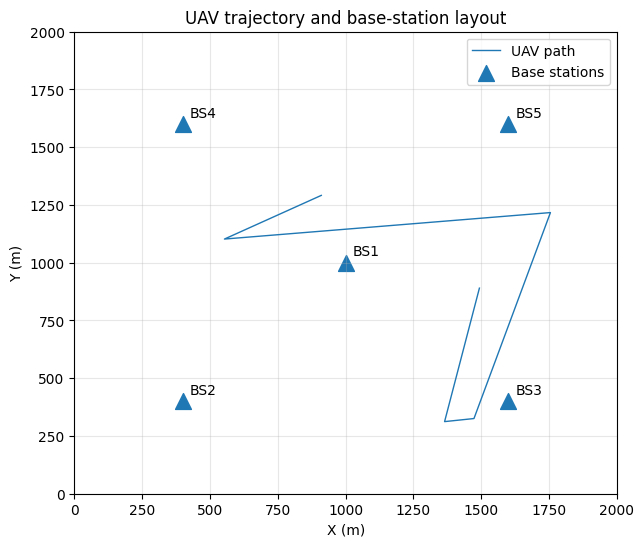

,bs_id,x_m,y_m,z_m
0,BS1,1000.0,1000.0,30.0
1,BS2,400.0,400.0,30.0
2,BS3,1600.0,400.0,30.0
3,BS4,400.0,1600.0,30.0
4,BS5,1600.0,1600.0,30.0


In [3]:
def create_base_stations(cfg):
    xy = [
        (0.50, 0.50), (0.20, 0.20), (0.80, 0.20),
        (0.20, 0.80), (0.80, 0.80)
    ]
    return pd.DataFrame([
        {"bs_id": f"BS{i+1}", "x_m": x*cfg.area_x_m,
         "y_m": y*cfg.area_y_m, "z_m": cfg.bs_height_m}
        for i, (x, y) in enumerate(xy)
    ])

def _random_waypoint(rng, cfg):
    return np.array([
        rng.uniform(100, cfg.area_x_m-100),
        rng.uniform(100, cfg.area_y_m-100),
        rng.uniform(cfg.drone_min_alt_m, cfg.drone_max_alt_m)
    ])

def generate_drone_trajectory(cfg, seed):
    rng = np.random.default_rng(seed)
    n = int(round(cfg.duration_s / cfg.dt_s))
    pos = np.zeros((n, 3))
    vel = np.zeros((n, 3))
    pos[0] = _random_waypoint(rng, cfg)
    waypoint = _random_waypoint(rng, cfg)
    speed = rng.uniform(cfg.min_speed_mps, cfg.max_speed_mps)

    for k in range(1, n):
        delta = waypoint - pos[k-1]
        distance = np.linalg.norm(delta)
        if distance < cfg.waypoint_reach_m:
            waypoint = _random_waypoint(rng, cfg)
            speed = rng.uniform(cfg.min_speed_mps, cfg.max_speed_mps)
            delta = waypoint - pos[k-1]
            distance = np.linalg.norm(delta)
        step = min(speed*cfg.dt_s, distance)
        direction = delta / max(distance, 1e-9)
        pos[k] = pos[k-1] + direction*step
        vel[k] = direction*(step/cfg.dt_s)

    heading = np.arctan2(vel[:, 1], vel[:, 0])
    return pd.DataFrame({
        "time_s": np.arange(n)*cfg.dt_s,
        "x_m": pos[:, 0], "y_m": pos[:, 1], "altitude_m": pos[:, 2],
        "vx_mps": vel[:, 0], "vy_mps": vel[:, 1], "vz_mps": vel[:, 2],
        "speed_mps": np.linalg.norm(vel, axis=1),
        "heading_sin": np.sin(heading), "heading_cos": np.cos(heading)
    })

BS = create_base_stations(CFG)
trajectory = generate_drone_trajectory(CFG, SEED)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(trajectory.x_m, trajectory.y_m, lw=1, label="UAV path")
ax.scatter(BS.x_m, BS.y_m, marker="^", s=130, label="Base stations")
for r in BS.itertuples():
    ax.annotate(r.bs_id, (r.x_m, r.y_m), xytext=(5, 5), textcoords="offset points")
ax.set(xlim=(0, CFG.area_x_m), ylim=(0, CFG.area_y_m),
       xlabel="X (m)", ylabel="Y (m)", title="UAV trajectory and base-station layout")
ax.grid(alpha=.3); ax.legend(); plt.show()
display(BS)

## 3. 3D distances and radio channel

The model includes reference-distance path loss, correlated log-normal shadowing, Rayleigh fading and full-reuse inter-cell interference. This is intentionally a compact comparative model, not a calibrated aerial 3GPP channel.

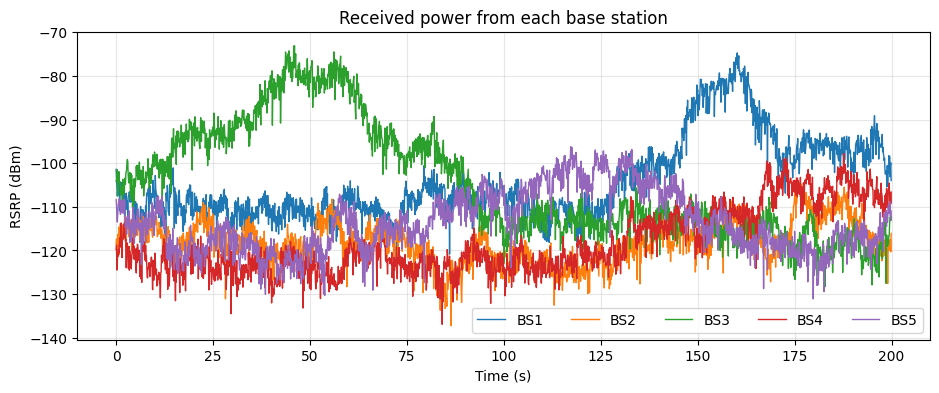

In [4]:
def calculate_distances(traj, bs):
    uav = traj[["x_m", "y_m", "altitude_m"]].to_numpy()[:, None, :]
    sites = bs[["x_m", "y_m", "z_m"]].to_numpy()[None, :, :]
    return np.linalg.norm(uav-sites, axis=2)

def generate_radio_measurements(traj, bs, cfg, seed):
    rng = np.random.default_rng(seed)
    d = calculate_distances(traj, bs)
    d0 = cfg.reference_distance_m
    pl0 = 32.4 + 20*np.log10(cfg.carrier_frequency_ghz) + 20*np.log10(d0)
    path_loss = pl0 + 10*cfg.path_loss_exponent*np.log10(np.maximum(d, d0)/d0)

    n, m = d.shape
    shadow = np.zeros((n, m))
    rho = 0.97
    for t in range(1, n):
        shadow[t] = rho*shadow[t-1] + np.sqrt(1-rho**2)*rng.normal(
            0, cfg.shadowing_std_db, m
        )

    h = (rng.normal(size=(n, m)) + 1j*rng.normal(size=(n, m)))/np.sqrt(2)
    fading = 10*np.log10(np.maximum(np.abs(h)**2, 1e-12))
    fading *= cfg.fading_std_db/5.57

    rsrp = cfg.tx_power_dbm - path_loss - shadow + fading
    rx_mw = 10**(rsrp/10)
    noise_mw = 10**(cfg.noise_power_dbm/10)
    interference = np.maximum(rx_mw.sum(axis=1, keepdims=True)-rx_mw, 0)
    sinr = 10*np.log10(np.maximum(rx_mw/(interference+noise_mw), 1e-12))

    return {"distances_m": d, "rsrp_dbm": rsrp, "sinr_db": sinr,
            "shadowing_db": shadow, "fading_db": fading}

radio = generate_radio_measurements(trajectory, BS, CFG, SEED+10_000)

fig, ax = plt.subplots(figsize=(11, 4))
for j, bs_id in enumerate(BS.bs_id):
    ax.plot(trajectory.time_s, radio["rsrp_dbm"][:, j], lw=1, label=bs_id)
ax.set(xlabel="Time (s)", ylabel="RSRP (dBm)", title="Received power from each base station")
ax.grid(alpha=.3); ax.legend(ncol=5); plt.show()

## 4. Handover engine

Corrections applied:
- TTT is reset if the trigger disappears **or the selected target changes**.
- A3 selects the strongest non-serving RSRP target.
- ISAC implements the communication **OR** distance trigger; if only sensing triggers, the nearest non-serving site becomes the candidate.
- LSTM selects its target using predicted RSRP, while actual RSRP is used to check target availability.
- A successful handover starts the configured interruption interval; throughput is zero during that interval.
- All strategies share the same mobility and radio arrays during evaluation.

In [5]:
def _best_index(values, exclude):
    candidates = np.flatnonzero(np.arange(len(values)) != exclude)
    return int(candidates[np.argmax(values[candidates])])

def run_handover_simulation(strategy, traj, bs, radio, ho_cfg, predicted_rsrp=None):
    strategy = strategy.upper()
    rsrp, dist, sinr = radio["rsrp_dbm"], radio["distances_m"], radio["sinr_db"]
    n, n_bs = rsrp.shape
    if n < 2 or len(traj) != n or len(bs) != n_bs:
        raise ValueError("Trajectory, radio arrays and base-station count do not match.")
    if strategy not in {"A3", "ISAC", "LSTM"}:
        raise ValueError("strategy must be A3, ISAC or LSTM")
    if strategy == "LSTM":
        if predicted_rsrp is None or predicted_rsrp.shape != rsrp.shape:
            raise ValueError("LSTM predictions must have shape (time_steps, number_of_BS).")

    time = traj["time_s"].to_numpy()
    serving = int(np.argmax(rsrp[0]))
    last_ho_time = -np.inf
    last_attempt_time = -np.inf
    interrupt_until = -np.inf
    pending_target, trigger_start = None, None
    events, records = [], []

    for t, now in enumerate(time):
        if strategy == "LSTM":
            pred = predicted_rsrp[t]
            valid_prediction = np.isfinite(pred).all()
            target = _best_index(pred, serving) if valid_prediction else serving
            trigger = bool(valid_prediction and
                           pred[target]-pred[serving] > ho_cfg.hysteresis_db)
            trigger_target = target
        else:
            comm_target = _best_index(rsrp[t], serving)
            comm_trigger = rsrp[t, comm_target]-rsrp[t, serving] > ho_cfg.hysteresis_db
            if strategy == "A3":
                trigger, trigger_target = bool(comm_trigger), comm_target
            else:
                near_target = int(np.argmin(np.where(
                    np.arange(n_bs) == serving, np.inf, dist[t]
                )))
                sensing_trigger = (
                    dist[t, serving]-dist[t, near_target] >
                    ho_cfg.distance_threshold_m
                )
                if comm_trigger:
                    trigger, trigger_target = True, comm_target
                elif sensing_trigger:
                    trigger, trigger_target = True, near_target
                else:
                    trigger, trigger_target = False, comm_target

        dwell_ok = now-last_ho_time >= ho_cfg.min_dwell_s
        retry_ok = now-last_attempt_time >= ho_cfg.retry_backoff_s
        attempt_ready = dwell_ok and retry_ok
        if trigger and attempt_ready:
            if pending_target != trigger_target:
                pending_target, trigger_start = trigger_target, now
        else:
            pending_target, trigger_start = None, None

        ho_attempt = False
        if (pending_target is not None and trigger_start is not None and
            now-trigger_start+1e-12 >= ho_cfg.ttt_s and attempt_ready):
            ho_attempt = True
            last_attempt_time = now
            target = pending_target
            quality = float(rsrp[t, target])
            success = quality >= ho_cfg.outage_rsrp_dbm
            source = serving
            events.append({
                "time_s": float(now), "source": bs.bs_id.iloc[source],
                "target": bs.bs_id.iloc[target], "success": bool(success),
                "target_rsrp_dbm": quality, "strategy": strategy
            })
            if success:
                serving = target
                last_ho_time = now
                interrupt_until = now + ho_cfg.interruption_s
            pending_target, trigger_start = None, None

        current_rsrp = float(rsrp[t, serving])
        current_sinr = float(sinr[t, serving])
        rate = CFG.bandwidth_hz/1e6 * np.log2(1 + 10**(current_sinr/10))
        in_interruption = now < interrupt_until
        if in_interruption:
            rate = 0.0

        records.append({
            "time_s": float(now), "serving_idx": serving,
            "serving_bs": bs.bs_id.iloc[serving],
            "serving_rsrp_dbm": current_rsrp,
            "serving_sinr_db": current_sinr,
            "throughput_mbps": float(rate),
            "outage": bool(current_rsrp < ho_cfg.outage_rsrp_dbm),
            "trigger_active": bool(trigger), "ho_attempt": bool(ho_attempt),
            "ho_interruption": bool(in_interruption)
        })

    return pd.DataFrame(records), events

## 5. Ping-pong detection and metrics

**Project definition:** a ping-pong is two consecutive successful handovers A→B and B→A whose time difference is no greater than `pingpong_window_s`. Failed attempts are excluded. This is an explicit simulation convention and should be stated in the report.

In [6]:
def detect_pingpong(events, window_s):
    successful = sorted(
        [e for e in events if e["success"]],
        key=lambda e: e["time_s"]
    )
    found = []
    for prev, curr in zip(successful[:-1], successful[1:]):
        delta = curr["time_s"]-prev["time_s"]
        if (prev["source"] == curr["target"] and
            prev["target"] == curr["source"] and
            0 <= delta <= window_s):
            found.append({
                "first_HO_time_s": prev["time_s"],
                "return_HO_time_s": curr["time_s"],
                "original_BS": prev["source"],
                "temporary_BS": prev["target"],
                "time_difference_s": delta
            })
    return len(found), pd.DataFrame(found)

def calculate_metrics(results, events, strategy, ho_cfg):
    attempts = len(events)
    failures = sum(not e["success"] for e in events)
    pp_count, _ = detect_pingpong(events, ho_cfg.pingpong_window_s)
    return {
        "Strategy": strategy,
        "HO attempts": attempts,
        "Successful HO": attempts-failures,
        "HO failures": failures,
        "HO failure rate (%)": 100*failures/max(attempts, 1),
        "Ping-pong events": pp_count,
        "Average throughput (Mbps)": results.throughput_mbps.mean(),
        "Outage ratio (%)": 100*results.outage.mean(),
        "Interruption ratio (%)": 100*results.ho_interruption.mean(),
        "Average serving RSRP (dBm)": results.serving_rsrp_dbm.mean()
    }

# Unit test: detector must identify BS1 -> BS2 -> BS1 within 2 seconds.
synthetic_events = [
    {"time_s": 1.0, "source": "BS1", "target": "BS2", "success": True},
    {"time_s": 2.5, "source": "BS2", "target": "BS1", "success": True}
]
assert detect_pingpong(synthetic_events, 2.0)[0] == 1
print("Ping-pong detector unit test passed.")

Ping-pong detector unit test passed.


## 6. Build LSTM training data without trajectory leakage

Each episode is generated with its own mobility seed and independent channel seed. Entire episodes—not randomly selected overlapping windows—are assigned to train or validation. The final evaluation episode uses a separate seed that is not used in either split.

The model receives only past samples. Inputs include mobility, circular heading encoding, distances and past RSRP. It predicts the RSRP vector at the next time step.

In [7]:
def make_episode(seed, cfg, bs):
    tr = generate_drone_trajectory(cfg, seed)
    rd = generate_radio_measurements(tr, bs, cfg, seed+50_000)
    return tr, rd

def build_feature_frame(traj, radio, bs):
    frame = traj[[
        "x_m", "y_m", "altitude_m", "speed_mps",
        "heading_sin", "heading_cos"
    ]].copy()
    for j, bs_id in enumerate(bs.bs_id):
        frame[f"distance_{bs_id}"] = radio["distances_m"][:, j]
        frame[f"rsrp_{bs_id}"] = radio["rsrp_dbm"][:, j]
    return frame.replace([np.inf, -np.inf], np.nan).ffill().fillna(0)

def make_windows(x, y, window):
    # X[t-window:t] predicts y[t].
    X = np.stack([x[i-window:i] for i in range(window, len(x))])
    Y = y[window:]
    return X.astype(np.float32), Y.astype(np.float32)

WINDOW = 20
TRAIN_SEEDS = [1000 + 37*i for i in range(10)]
VAL_SEEDS = [5000 + 41*i for i in range(3)]

train_frames = [build_feature_frame(*make_episode(s, CFG, BS), BS) for s in TRAIN_SEEDS]
val_frames = [build_feature_frame(*make_episode(s, CFG, BS), BS) for s in VAL_SEEDS]

target_cols = [f"rsrp_{b}" for b in BS.bs_id]
feature_cols = list(train_frames[0].columns)

# Fit both scalers on training episodes only.
x_train_raw = np.concatenate([f[feature_cols].to_numpy() for f in train_frames])
y_train_raw = np.concatenate([f[target_cols].to_numpy() for f in train_frames])
x_mu, x_sigma = x_train_raw.mean(0), x_train_raw.std(0)
y_mu, y_sigma = y_train_raw.mean(0), y_train_raw.std(0)
x_sigma[x_sigma < 1e-8] = 1.0
y_sigma[y_sigma < 1e-8] = 1.0

def episode_windows(frame):
    x = (frame[feature_cols].to_numpy(np.float32)-x_mu)/x_sigma
    y = (frame[target_cols].to_numpy(np.float32)-y_mu)/y_sigma
    return make_windows(x, y, WINDOW)

train_pairs = [episode_windows(f) for f in train_frames]
val_pairs = [episode_windows(f) for f in val_frames]
X_train = np.concatenate([p[0] for p in train_pairs])
y_train = np.concatenate([p[1] for p in train_pairs])
X_val = np.concatenate([p[0] for p in val_pairs])
y_val = np.concatenate([p[1] for p in val_pairs])

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Training trajectory seeds:", TRAIN_SEEDS)
print("Validation trajectory seeds:", VAL_SEEDS)

Train: (19800, 20, 16) (19800, 5)
Validation: (5940, 20, 16) (5940, 5)
Training trajectory seeds: [1000, 1037, 1074, 1111, 1148, 1185, 1222, 1259, 1296, 1333]
Validation trajectory seeds: [5000, 5041, 5082]


## 7. Train the LSTM

A compact two-layer LSTM is used as a baseline. Early stopping selects the best validation-loss epoch. The held-out evaluation episode is not used for fitting or early stopping.

Epoch 1/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - loss: 0.2305 - mae: 0.3523 - val_loss: 0.2324 - val_mae: 0.3248
Epoch 2/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - loss: 0.1036 - mae: 0.2497 - val_loss: 0.1703 - val_mae: 0.2884
Epoch 3/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0912 - mae: 0.2339 - val_loss: 0.1405 - val_mae: 0.2672
Epoch 4/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0871 - mae: 0.2281 - val_loss: 0.1306 - val_mae: 0.2583
Epoch 5/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0844 - mae: 0.2243 - val_loss: 0.1207 - val_mae: 0.2520
Epoch 6/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0828 - mae: 0.2220 - val_loss: 0.1160 - val_mae: 0.2473
Epoch 7/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0816 - mae: 0.2202 - val_loss: 0.1142 - val_mae: 0.2462
Epoch 8/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0805 - mae: 0.2187 - val_loss: 0.1113 - val_mae: 0.2434
Epoch 9/30
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/

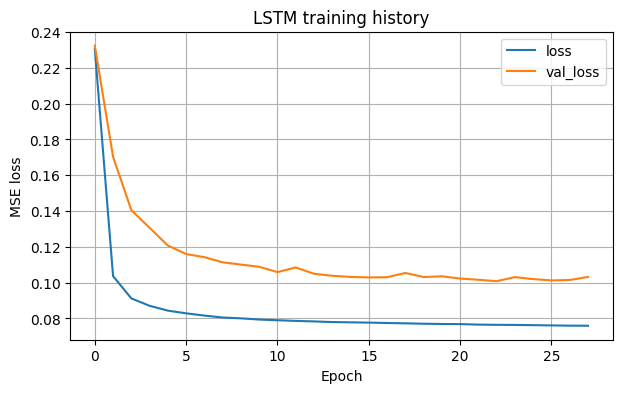

In [8]:
from tensorflow.keras import layers, models, callbacks

model = models.Sequential([
    layers.Input(shape=(WINDOW, X_train.shape[-1])),
    layers.LSTM(48, return_sequences=True),
    layers.Dropout(0.15),
    layers.LSTM(24),
    layers.Dense(len(target_cols))
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="mse", metrics=["mae"])

early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
history = model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=30, batch_size=128, callbacks=[early_stop], verbose=1
)

pd.DataFrame(history.history)[["loss", "val_loss"]].plot(
    figsize=(7, 4), title="LSTM training history", grid=True
)
plt.xlabel("Epoch"); plt.ylabel("MSE loss"); plt.show()

## 8. Create one independent final evaluation episode

This seed is deliberately outside the training and validation seed lists. A3, ISAC and LSTM will all be evaluated on this exact same trajectory and radio realization.

In [9]:
EVAL_TRAJ_SEED = 90001
EVAL_RADIO_SEED = 190001

assert EVAL_TRAJ_SEED not in TRAIN_SEEDS + VAL_SEEDS

eval_trajectory = generate_drone_trajectory(CFG, EVAL_TRAJ_SEED)
eval_radio = generate_radio_measurements(
    eval_trajectory, BS, CFG, EVAL_RADIO_SEED
)
eval_frame = build_feature_frame(eval_trajectory, eval_radio, BS)

x_eval = (eval_frame[feature_cols].to_numpy(np.float32)-x_mu)/x_sigma
y_eval_actual = eval_radio["rsrp_dbm"]

# Batched sliding windows: each past WINDOW samples predict the next sample.
eval_windows = np.stack([
    x_eval[i-WINDOW:i] for i in range(WINDOW, len(x_eval))
]).astype(np.float32)

pred_norm = model.predict(eval_windows, batch_size=256, verbose=0)
pred_eval = np.full_like(y_eval_actual, np.nan, dtype=np.float32)
pred_eval[WINDOW:] = pred_norm*y_sigma + y_mu

print("Evaluation trajectory seed:", EVAL_TRAJ_SEED)
print("Evaluation radio seed:", EVAL_RADIO_SEED)
print("Evaluation samples:", len(eval_trajectory))

Evaluation trajectory seed: 90001
Evaluation radio seed: 190001
Evaluation samples: 2000


## 9. Independent LSTM prediction accuracy

The first `WINDOW` samples are warm-up history and are excluded from prediction-error calculations. No actual RSRP values are substituted as model predictions.

,Base station,MAE (dB),RMSE (dB)
0,rsrp_BS1,1.927,2.492
1,rsrp_BS2,1.999,2.573
2,rsrp_BS3,1.884,2.456
3,rsrp_BS4,1.890,2.409
4,rsrp_BS5,1.896,2.447


Overall MAE: 1.919 dB
Overall RMSE: 2.476 dB


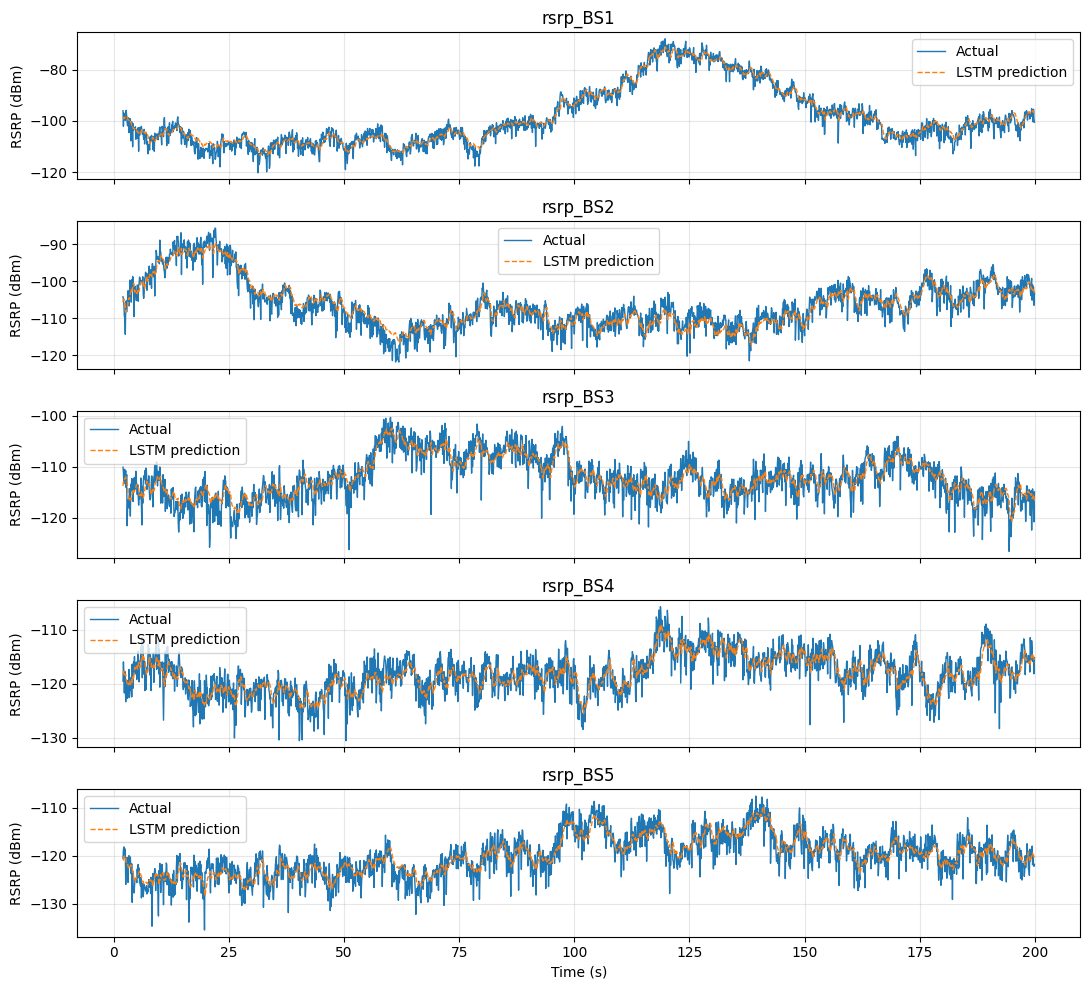

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = y_eval_actual[WINDOW:]
predicted = pred_eval[WINDOW:]
mae_each = mean_absolute_error(actual, predicted, multioutput="raw_values")
rmse_each = np.sqrt(mean_squared_error(actual, predicted, multioutput="raw_values"))

prediction_report = pd.DataFrame({
    "Base station": target_cols,
    "MAE (dB)": mae_each,
    "RMSE (dB)": rmse_each
})
display(prediction_report.round(3))
print("Overall MAE:", round(mean_absolute_error(actual, predicted), 3), "dB")
print("Overall RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 3), "dB")

fig, axes = plt.subplots(len(target_cols), 1, figsize=(11, 10), sharex=True)
for j, ax in enumerate(axes):
    ax.plot(eval_trajectory.time_s.iloc[WINDOW:], actual[:, j],
            label="Actual", lw=1)
    ax.plot(eval_trajectory.time_s.iloc[WINDOW:], predicted[:, j],
            label="LSTM prediction", lw=1, ls="--")
    ax.set_ylabel("RSRP (dBm)")
    ax.set_title(target_cols[j])
    ax.grid(alpha=.3); ax.legend()
axes[-1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

## 10. Run all three strategies on the same held-out episode

The LSTM is in warm-up during the first `WINDOW` samples; it simply does not initiate predictive handovers during that interval. A3 and ISAC still use the same complete radio trace. The common initial serving cell is selected from the same first-sample RSRP vector.

In [11]:
results_a3, events_a3 = run_handover_simulation(
    "A3", eval_trajectory, BS, eval_radio, HO_CFG
)
results_isac, events_isac = run_handover_simulation(
    "ISAC", eval_trajectory, BS, eval_radio, HO_CFG
)
results_lstm, events_lstm = run_handover_simulation(
    "LSTM", eval_trajectory, BS, eval_radio, HO_CFG,
    predicted_rsrp=pred_eval
)

events_by_strategy = {
    "Traditional A3": events_a3,
    "ISAC-assisted": events_isac,
    "LSTM predictive": events_lstm
}
results_by_strategy = {
    "Traditional A3": results_a3,
    "ISAC-assisted": results_isac,
    "LSTM predictive": results_lstm
}

for name, events in events_by_strategy.items():
    print(f"\n{name}: {len(events)} attempts")
    display(pd.DataFrame(events))


Traditional A3: 8 attempts


,time_s,source,target,success,target_rsrp_dbm,strategy
0,7.2,BS1,BS2,True,-102.437555,A3
1,56.0,BS2,BS1,True,-104.365313,A3
2,59.8,BS1,BS3,True,-102.409211,A3
3,74.8,BS3,BS1,True,-103.630689,A3
4,78.8,BS1,BS3,True,-103.950288,A3
5,81.6,BS3,BS1,True,-104.361108,A3
6,176.2,BS1,BS2,True,-96.858378,A3
7,195.5,BS2,BS1,True,-98.494510,A3



ISAC-assisted: 9 attempts


,time_s,source,target,success,target_rsrp_dbm,strategy
0,7.2,BS1,BS2,True,-102.437555,ISAC
1,56.0,BS2,BS1,True,-104.365313,ISAC
2,57.5,BS1,BS3,False,-105.471053,ISAC
3,59.0,BS1,BS3,True,-100.698527,ISAC
4,74.8,BS3,BS1,True,-103.630689,ISAC
5,78.8,BS1,BS3,True,-103.950288,ISAC
6,81.6,BS3,BS1,True,-104.361108,ISAC
7,176.2,BS1,BS2,True,-96.858378,ISAC
8,187.5,BS2,BS1,True,-100.358290,ISAC



LSTM predictive: 10 attempts


,time_s,source,target,success,target_rsrp_dbm,strategy
0,6.1,BS1,BS2,True,-100.007429,LSTM
1,56.2,BS2,BS1,True,-104.992389,LSTM
2,59.2,BS1,BS3,False,-105.497241,LSTM
3,60.7,BS1,BS3,True,-104.273550,LSTM
4,73.1,BS3,BS1,True,-102.525170,LSTM
5,79.0,BS1,BS3,True,-102.975037,LSTM
6,80.6,BS3,BS2,False,-105.719276,LSTM
7,82.1,BS3,BS1,True,-103.633822,LSTM
8,176.5,BS1,BS2,True,-96.647807,LSTM
9,185.9,BS2,BS1,True,-101.685319,LSTM


## 11. Calculate and compare performance metrics

Throughput already includes the configured interruption after each successful handover. Do not apply another interruption in plotting or post-processing; that would double-count it.

In [12]:
comparison = pd.DataFrame([
    calculate_metrics(results_by_strategy[name], events_by_strategy[name], name, HO_CFG)
    for name in results_by_strategy
])
display(comparison.round(3))

for name, events in events_by_strategy.items():
    count, details = detect_pingpong(events, HO_CFG.pingpong_window_s)
    print(f"{name}: {count} ping-pong event(s), window={HO_CFG.pingpong_window_s:.1f} s")
    if count:
        display(details)

,Strategy,HO attempts,Successful HO,HO failures,HO failure rate (%),Ping-pong events,Average throughput (Mbps),Outage ratio (%),Interruption ratio (%),Average serving RSRP (dBm)
0,Traditional A3,8,8,0,0.000,2,9.263,23.45,0.4,-96.741
1,ISAC-assisted,9,8,1,11.111,2,9.273,23.05,0.4,-96.691
2,LSTM predictive,10,8,2,20.000,1,9.274,23.10,0.4,-96.706


Traditional A3: 2 ping-pong event(s), window=5.0 s


,first_HO_time_s,return_HO_time_s,original_BS,temporary_BS,time_difference_s
0,74.8,78.8,BS3,BS1,4.0
1,78.8,81.6,BS1,BS3,2.8


ISAC-assisted: 2 ping-pong event(s), window=5.0 s


,first_HO_time_s,return_HO_time_s,original_BS,temporary_BS,time_difference_s
0,74.8,78.8,BS3,BS1,4.0
1,78.8,81.6,BS1,BS3,2.8


LSTM predictive: 1 ping-pong event(s), window=5.0 s


,first_HO_time_s,return_HO_time_s,original_BS,temporary_BS,time_difference_s
0,79.0,82.1,BS1,BS3,3.1


## 12. Visual comparison

Separate throughput panels prevent one strategy's line from hiding another. The zero-throughput segments are the handover interruption periods already included in the simulation.

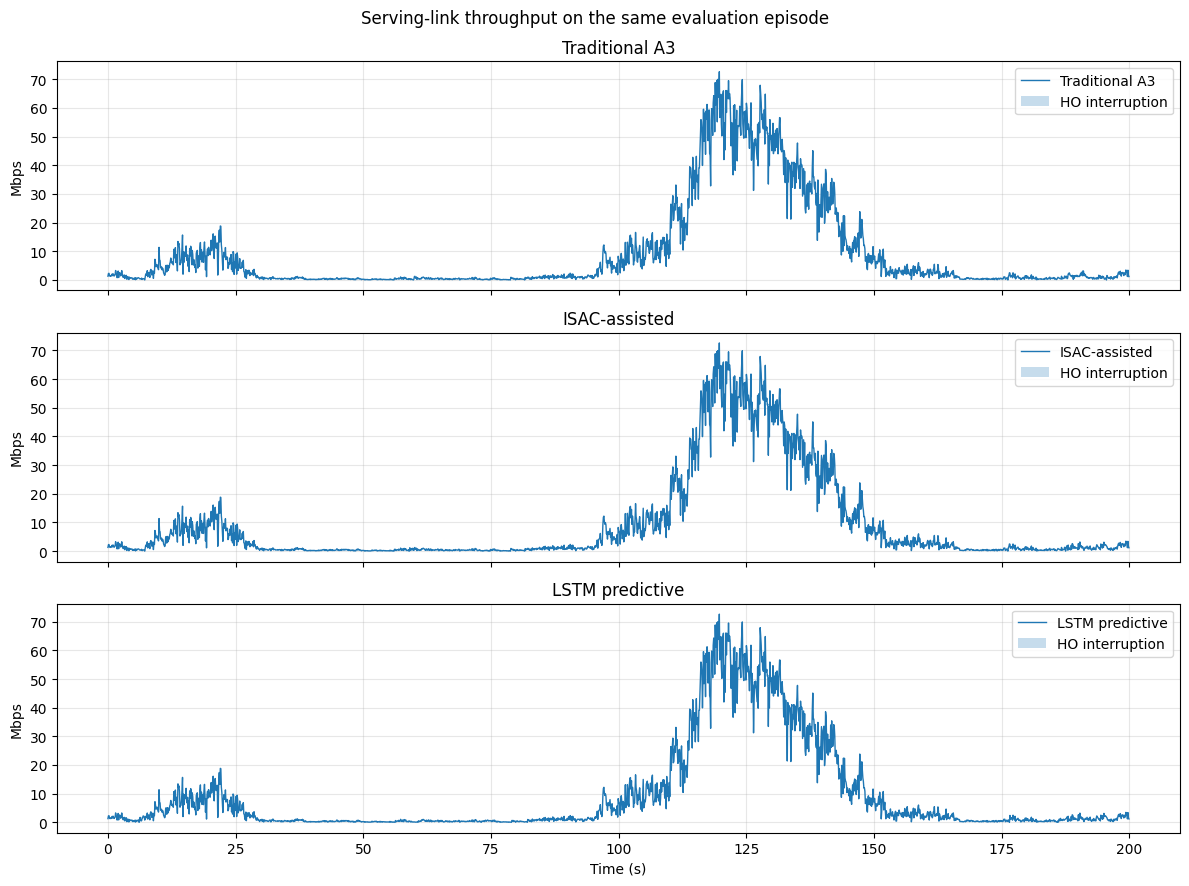

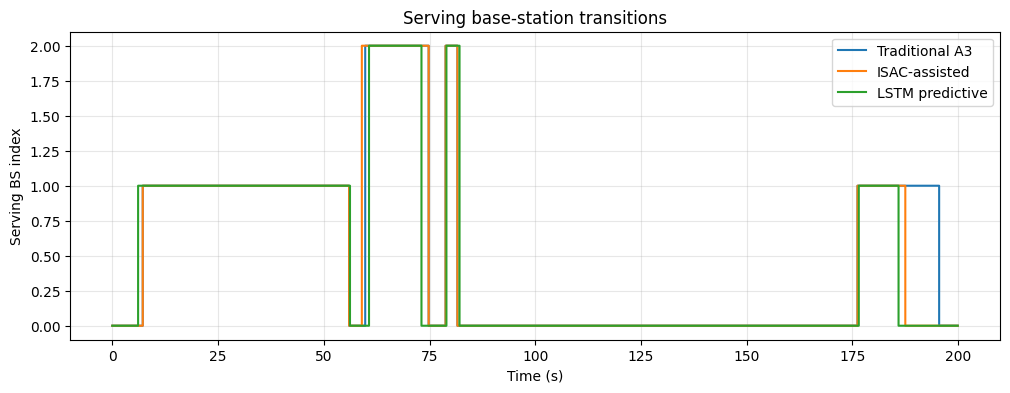

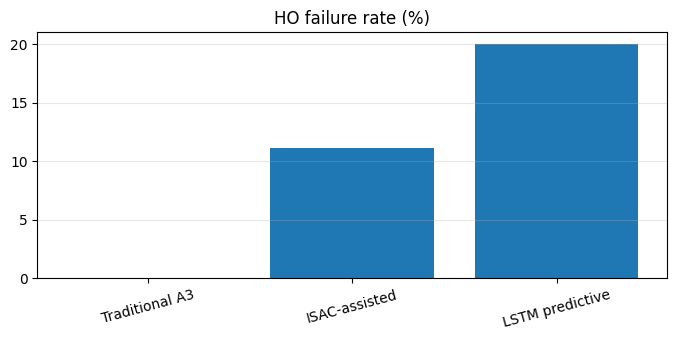

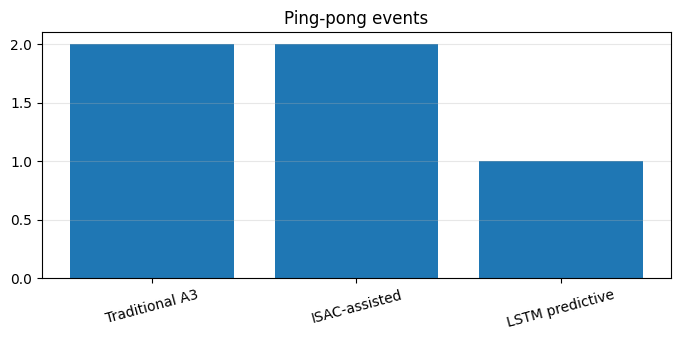

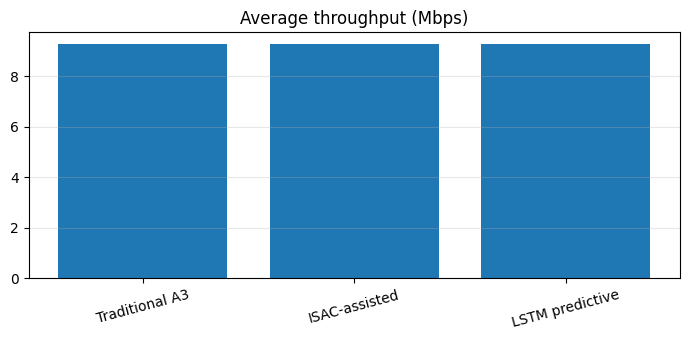

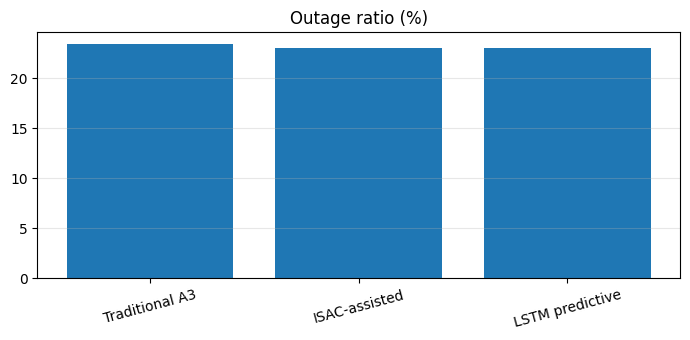

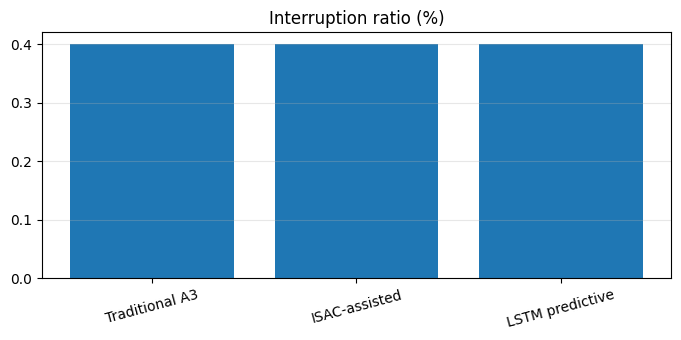

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (name, res) in zip(axes, results_by_strategy.items()):
    ax.plot(res.time_s, res.throughput_mbps, lw=1, label=name)
    ax.fill_between(
        res.time_s, 0, res.throughput_mbps,
        where=res.ho_interruption, alpha=.25, label="HO interruption"
    )
    ax.set_ylabel("Mbps"); ax.set_title(name)
    ax.grid(alpha=.3); ax.legend()
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Serving-link throughput on the same evaluation episode")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
for name, res in results_by_strategy.items():
    ax.step(res.time_s, res.serving_idx, where="post", label=name)
ax.set(xlabel="Time (s)", ylabel="Serving BS index",
       title="Serving base-station transitions")
ax.grid(alpha=.3); ax.legend(); plt.show()

metric_cols = [
    "HO failure rate (%)", "Ping-pong events",
    "Average throughput (Mbps)", "Outage ratio (%)",
    "Interruption ratio (%)"
]
for col in metric_cols:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(comparison["Strategy"], comparison[col])
    ax.set_title(col); ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

## 13. Inspect serving-cell transitions and handover events

This makes it easier to distinguish a genuinely zero ping-pong result from an event-logging or metric issue.

In [14]:
for name, res in results_by_strategy.items():
    changes = res.loc[res.serving_idx.ne(res.serving_idx.shift()),
                      ["time_s", "serving_bs"]]
    print(f"\n{name} serving-cell changes:")
    display(changes.reset_index(drop=True))
    pp_count, pp_table = detect_pingpong(
        events_by_strategy[name], HO_CFG.pingpong_window_s
    )
    print("Detected ping-pong:", pp_count)


Traditional A3 serving-cell changes:


,time_s,serving_bs
0,0.0,BS1
1,7.2,BS2
2,56.0,BS1
3,59.8,BS3
4,74.8,BS1
5,78.8,BS3
6,81.6,BS1
7,176.2,BS2
8,195.5,BS1


Detected ping-pong: 2

ISAC-assisted serving-cell changes:


,time_s,serving_bs
0,0.0,BS1
1,7.2,BS2
2,56.0,BS1
3,59.0,BS3
4,74.8,BS1
5,78.8,BS3
6,81.6,BS1
7,176.2,BS2
8,187.5,BS1


Detected ping-pong: 2

LSTM predictive serving-cell changes:


,time_s,serving_bs
0,0.0,BS1
1,6.1,BS2
2,56.2,BS1
3,60.7,BS3
4,73.1,BS1
5,79.0,BS3
6,82.1,BS1
7,176.5,BS2
8,185.9,BS1


Detected ping-pong: 1


## 14. Export reproducible results

The output folder contains the held-out trajectory, radio measurements, per-strategy time series, event logs, prediction errors and comparison table.

In [15]:
os.makedirs("results", exist_ok=True)

dataset = eval_trajectory.reset_index(drop=True).copy()
for j, bs_id in enumerate(BS.bs_id):
    dataset[f"distance_{bs_id}"] = eval_radio["distances_m"][:, j]
    dataset[f"rsrp_{bs_id}"] = eval_radio["rsrp_dbm"][:, j]
    dataset[f"sinr_{bs_id}"] = eval_radio["sinr_db"][:, j]
    dataset[f"predicted_rsrp_{bs_id}"] = pred_eval[:, j]

dataset.to_csv("results/evaluation_dataset.csv", index=False)
comparison.to_csv("results/algorithm_comparison.csv", index=False)
prediction_report.to_csv("results/lstm_prediction_errors.csv", index=False)

for key, res in results_by_strategy.items():
    slug = key.lower().replace(" ", "_").replace("-", "_")
    res.to_csv(f"results/{slug}_timeseries.csv", index=False)
    pd.DataFrame(events_by_strategy[key]).to_csv(
        f"results/{slug}_handover_events.csv", index=False
    )

print("Saved:", sorted(os.listdir("results")))

Saved: ['algorithm_comparison.csv', 'evaluation_dataset.csv', 'isac_assisted_handover_events.csv', 'isac_assisted_timeseries.csv', 'lstm_prediction_errors.csv', 'lstm_predictive_handover_events.csv', 'lstm_predictive_timeseries.csv', 'traditional_a3_handover_events.csv', 'traditional_a3_timeseries.csv']


## 15. Recommended controlled experiments

For the final report, repeat the comparison over multiple independent evaluation seeds and report mean ± standard deviation. Keep each algorithm on identical trajectory/channel realizations within each seed.

Suggested one-factor-at-a-time sweeps:
- UAV speed and altitude.
- Hysteresis and TTT.
- ISAC distance threshold.
- Shadowing and fading variability.
- Ping-pong window (report the chosen definition explicitly).

**Interpretation cautions**
- Zero ping-pong is a valid result; do not tune parameters merely to force a nonzero count.
- The distance trigger uses idealized true distance, not noisy ISAC range estimates.
- The RSRP availability threshold and channel parameters require justification.
- The Shannon-style rate is an estimate, not measured 5G user throughput.
- A one-step LSTM trained on synthetic channels does not establish real-network generalization.
- A lower handover count is not automatically better; interpret it alongside outage, failure, interruption and throughput.